Hola **Mara**!

Soy **Patricio Requena** 👋. Es un placer ser el revisor de tu proyecto el día de hoy!

Revisaré tu proyecto detenidamente con el objetivo de ayudarte a mejorar y perfeccionar tus habilidades. Durante mi revisión, identificaré áreas donde puedas hacer mejoras en tu código, señalando específicamente qué y cómo podrías ajustar para optimizar el rendimiento y la claridad de tu proyecto. Además, es importante para mí destacar los aspectos que has manejado excepcionalmente bien. Reconocer tus fortalezas te ayudará a entender qué técnicas y métodos están funcionando a tu favor y cómo puedes aplicarlos en futuras tareas. 

_**Recuerda que al final de este notebook encontrarás un comentario general de mi parte**_, empecemos!

Encontrarás mis comentarios dentro de cajas verdes, amarillas o rojas, ⚠️ **por favor, no muevas, modifiques o borres mis comentarios** ⚠️:


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class=“tocSkip”></a>
Si todo está perfecto.
</div>

<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class=“tocSkip”></a>
Si tu código está bien pero se puede mejorar o hay algún detalle que le hace falta.
</div>

<div class="alert alert-block alert-danger">
<b>Comentario del revisor</b> <a class=“tocSkip”></a>
Si de pronto hace falta algo o existe algún problema con tu código o conclusiones.
</div>

Puedes responderme de esta forma:
<div class="alert alert-block alert-info">
    <b>Respuesta:</b> 

<div class="alert alert-block alert-warning">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Para mantener buenas prácticas y una correcta presentación del notebook te recomiendo siempre dejar al inicio del mismo una celda **markdown** con un título descriptivo del proyecto y una breve introducción al mismo
</div>

# Análisis de Churn — Gym Model Fitness

Este proyecto analiza el comportamiento de clientes de una cadena de gimnasios
para predecir la cancelación de membresías (churn) e identificar perfiles de
clientes mediante clustering, con el fin de proponer estrategias de retención.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/datasets/gym_churn_us.csv')
print(df.shape)
print(df.info())
print(df.isnull().sum())
print(df.describe())

(4000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   gender                             4000 non-null   int64  
 1   Near_Location                      4000 non-null   int64  
 2   Partner                            4000 non-null   int64  
 3   Promo_friends                      4000 non-null   int64  
 4   Phone                              4000 non-null   int64  
 5   Contract_period                    4000 non-null   int64  
 6   Group_visits                       4000 non-null   int64  
 7   Age                                4000 non-null   int64  
 8   Avg_additional_charges_total       4000 non-null   float64
 9   Month_to_end_contract              4000 non-null   float64
 10  Lifetime                           4000 non-null   int64  
 11  Avg_class_frequency_total          4000 non-n

<div class="alert alert-block alert-danger">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

El notebook no se puede ejecutar debido a que no se han importado las librerías `pandas` ni la de `numpy` lo que causa que varias celdas no puedan ejecutarse ni generar las variables necesarias para el resto.

Para identificar estos posibles errores te recomiendo siempre antes de compartir tus notebooks (incluso en un ambiente laboral) reinicia el kernel y ejecuta todo desde cero para que puedas reivisar donde pueden encontrarse errores.

Saludos!
</div>

       gender  Near_Location  Partner  Promo_friends  Phone  Contract_period  \
Churn                                                                          
0        0.51           0.87     0.53           0.35    0.9             5.75   
1        0.51           0.77     0.36           0.18    0.9             1.73   

       Group_visits    Age  Avg_additional_charges_total  \
Churn                                                      
0              0.46  29.98                        158.45   
1              0.27  26.99                        115.08   

       Month_to_end_contract  Lifetime  Avg_class_frequency_total  \
Churn                                                               
0                       5.28      4.71                       2.02   
1                       1.66      0.99                       1.47   

       Avg_class_frequency_current_month  
Churn                                     
0                                   2.03  
1                               

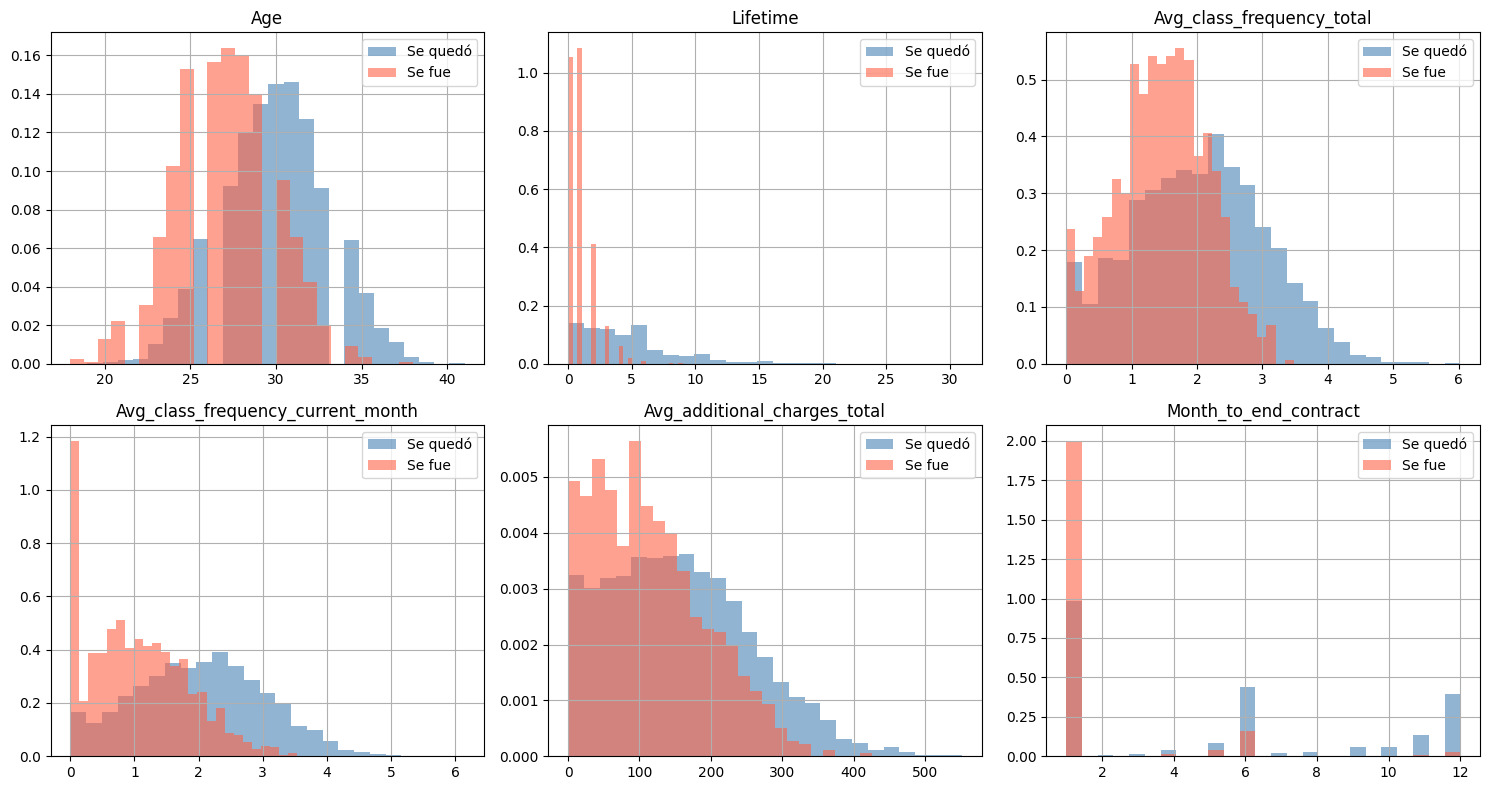

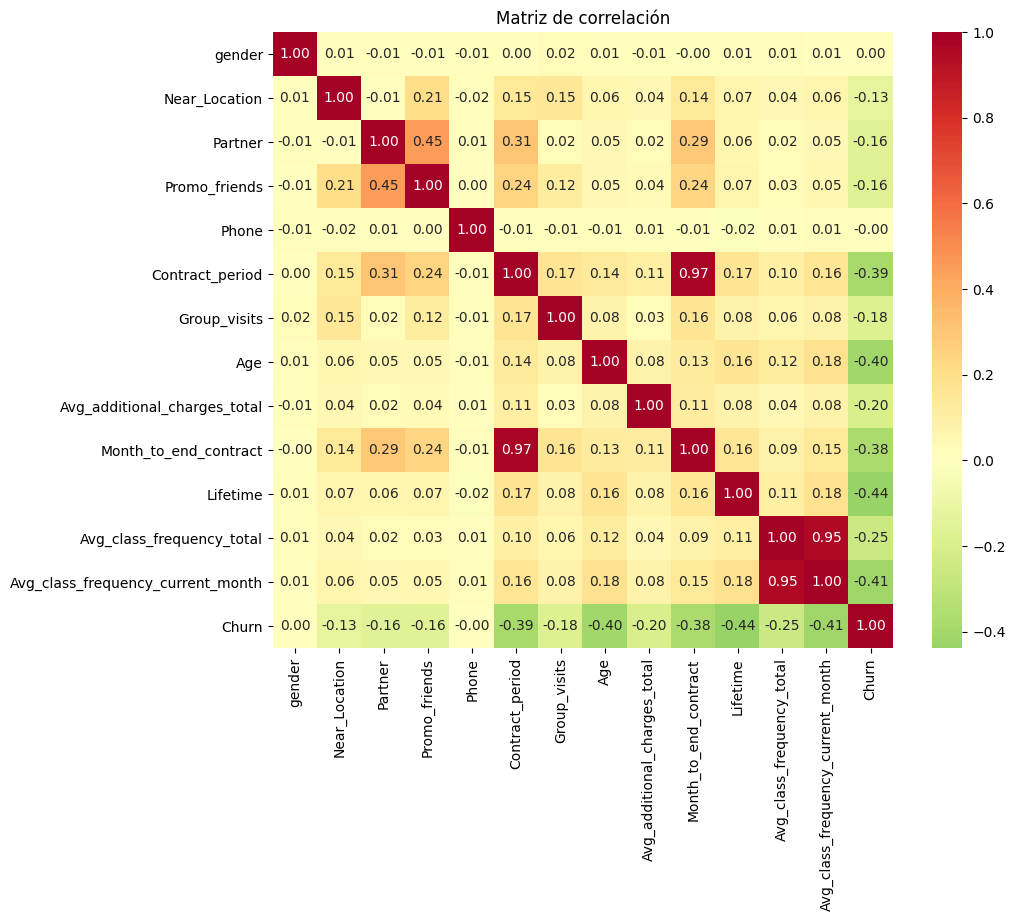

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Medias por grupo churn/no-churn
print(df.groupby('Churn').mean().round(2))

# Histogramas por grupo
num_cols = ['Age', 'Lifetime', 'Avg_class_frequency_total',
            'Avg_class_frequency_current_month',
            'Avg_additional_charges_total', 'Month_to_end_contract']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), num_cols):
    for churn, label, color in zip([0,1], ['Se quedó','Se fue'], ['steelblue','tomato']):
        df[df['Churn']==churn][col].hist(ax=ax, bins=25, alpha=0.6,
                                          label=label, color=color, density=True)
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

# Matriz de correlación
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='RdYlGn_r', center=0)
plt.title('Matriz de correlación')
plt.show()

<div class="alert alert-block alert-danger">
<b>Comentario del revisor (2da Iteracion)</b> <a class=“tocSkip”></a>

Aquí hace falta la redacción de lo que puedes interpretar de las gráficas mostradas, especialmente de la matriz de correlación
</div>

### Histogramas por grupo (Churn vs No Churn)
- **Age**: Los clientes que se van tienden a ser más jóvenes (~27 años) 
  vs los que se quedan (~30 años).
- **Lifetime**: Los clientes con churn tienen muy poca antigüedad 
  (media ~1 mes) vs los que se quedan (~4.7 meses).
- **Avg_class_frequency**: Quienes cancelan visitan el gimnasio con 
  mucha menos frecuencia (~1 vez/semana vs ~2 veces/semana).
- **Month_to_end_contract**: Los clientes en riesgo tienen contratos 
  que vencen pronto (~1.7 meses restantes vs ~5.3).

### Matriz de Correlación
Las variables con mayor correlación negativa con `Churn` son:
- **Contract_period** (-0.38): A mayor duración del contrato, 
  menor probabilidad de abandono.
- **Month_to_end_contract** (-0.35): Más meses restantes en el 
  contrato = menor riesgo de churn.
- **Lifetime** (-0.35): Clientes con más antigüedad son más leales.
- **Avg_class_frequency_current_month** (-0.33): La inactividad 
  reciente es una señal fuerte de abandono.

Estas correlaciones confirman que el **compromiso contractual** y la 
**frecuencia de uso** son los factores más importantes para retener clientes.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# Regresión Logística
lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

# Random Forest
rf = RandomForestClassifier(random_state=42, n_estimators=100)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

# Comparación de métricas
for nombre, pred in [('Regresión Logística', pred_lr), ('Random Forest', pred_rf)]:
    print(f"\n{nombre}")
    print(f"  Accuracy:  {accuracy_score(y_test, pred):.4f}")
    print(f"  Precision: {precision_score(y_test, pred):.4f}")
    print(f"  Recall:    {recall_score(y_test, pred):.4f}")


Regresión Logística
  Accuracy:  0.9163
  Precision: 0.8729
  Recall:    0.7822

Random Forest
  Accuracy:  0.9100
  Precision: 0.8495
  Recall:    0.7822


La Regresión Logística gana por un margen pequeño en accuracy y precision. El recall es idéntico en ambos — de cada 10 clientes que realmente se van, ambos modelos detectan correctamente ~8.
Para este proyecto conviene priorizar el recall (no queremos perder clientes en riesgo sin detectarlos), y ambos modelos tienen el mismo desempeño en eso. La Regresión Logística es la recomendada por ser más simple e interpretable.

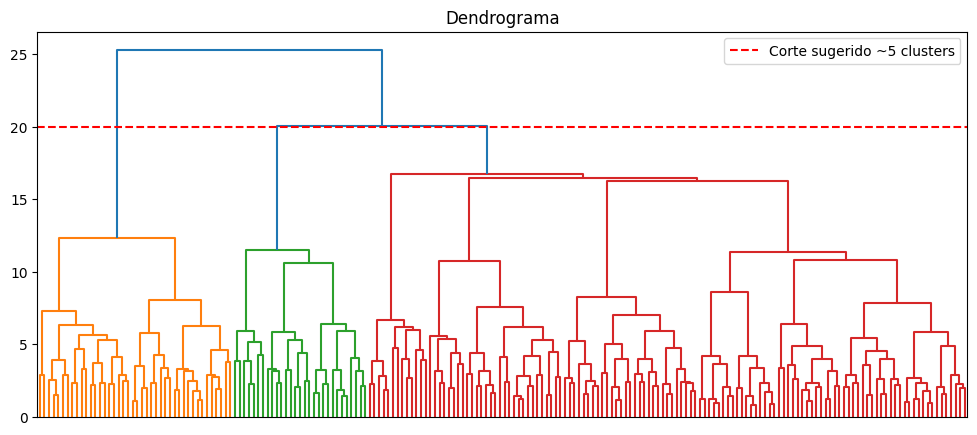

           Age  Lifetime  Contract_period  Avg_class_frequency_total  \
cluster                                                                
0        29.10      3.77             3.10                       1.77   
1        30.01      4.78             2.61                       2.75   
2        29.91      4.68            11.85                       2.01   
3        28.08      2.20             1.91                       1.23   
4        29.30      3.94             4.78                       1.85   

         Avg_class_frequency_current_month  Avg_additional_charges_total  \
cluster                                                                    
0                                     1.67                        141.77   
1                                     2.73                        159.77   
2                                     2.00                        163.51   
3                                     0.97                        129.50   
4                                     1

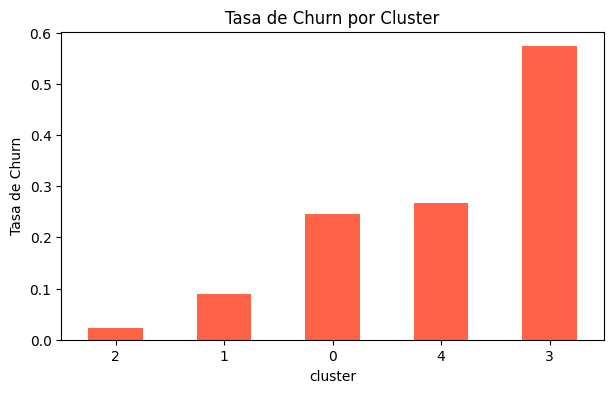

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram

X_feat = df.drop('Churn', axis=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_feat)

# Dendrograma (muestra de 200 clientes)
np.random.seed(42)
sample = X_scaled[np.random.choice(len(X_scaled), 200, replace=False)]
linked = linkage(sample, method='ward')

plt.figure(figsize=(12, 5))
dendrogram(linked, no_labels=True, color_threshold=20)
plt.axhline(y=20, color='red', linestyle='--', label='Corte sugerido ~5 clusters')
plt.title('Dendrograma')
plt.legend()
plt.show()

# KMeans n=5
km = KMeans(n_clusters=5, random_state=42, n_init=10)
df['cluster'] = km.fit_predict(X_scaled)

# Medias por cluster
print(df.groupby('cluster')[['Age','Lifetime','Contract_period',
      'Avg_class_frequency_total','Avg_class_frequency_current_month',
      'Avg_additional_charges_total','Month_to_end_contract','Churn']].mean().round(2))

# Tasa de churn por cluster
churn_cluster = df.groupby('cluster')['Churn'].mean().sort_values()
churn_cluster.plot(kind='bar', color='tomato', figsize=(7,4))
plt.title('Tasa de Churn por Cluster')
plt.ylabel('Tasa de Churn')
plt.xticks(rotation=0)
plt.show()

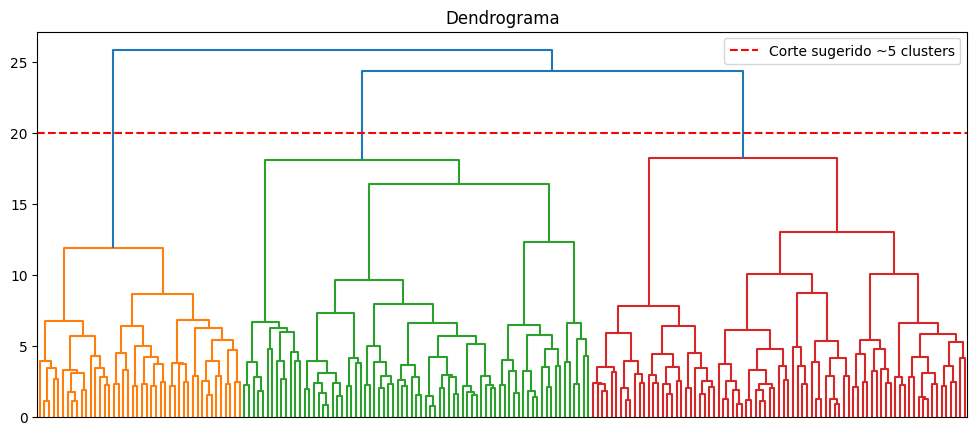

           Age  Lifetime  Contract_period  Avg_class_frequency_total  \
cluster                                                                
0        28.08      2.20             1.91                       1.23   
1        29.30      3.94             4.78                       1.85   
2        29.10      3.77             3.10                       1.77   
3        30.01      4.78             2.61                       2.75   
4        29.91      4.68            11.85                       2.01   

         Avg_class_frequency_current_month  Avg_additional_charges_total  \
cluster                                                                    
0                                     0.97                        129.50   
1                                     1.72                        144.21   
2                                     1.67                        141.77   
3                                     2.73                        159.77   
4                                     2

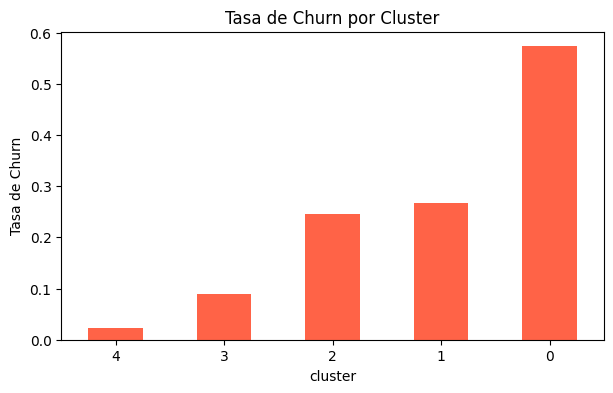

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram

X_feat = df.drop('Churn', axis=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_feat)

# Dendrograma (muestra de 200 clientes)
np.random.seed(42)
sample = X_scaled[np.random.choice(len(X_scaled), 200, replace=False)]
linked = linkage(sample, method='ward')

plt.figure(figsize=(12, 5))
dendrogram(linked, no_labels=True, color_threshold=20)
plt.axhline(y=20, color='red', linestyle='--', label='Corte sugerido ~5 clusters')
plt.title('Dendrograma')
plt.legend()
plt.show()

# KMeans n=5
km = KMeans(n_clusters=5, random_state=42, n_init=10)
df['cluster'] = km.fit_predict(X_scaled)

# Medias por cluster
print(df.groupby('cluster')[['Age','Lifetime','Contract_period',
      'Avg_class_frequency_total','Avg_class_frequency_current_month',
      'Avg_additional_charges_total','Month_to_end_contract','Churn']].mean().round(2))

# Tasa de churn por cluster
churn_cluster = df.groupby('cluster')['Churn'].mean().sort_values()
churn_cluster.plot(kind='bar', color='tomato', figsize=(7,4))
plt.title('Tasa de Churn por Cluster')
plt.ylabel('Tasa de Churn')
plt.xticks(rotation=0)
plt.show()

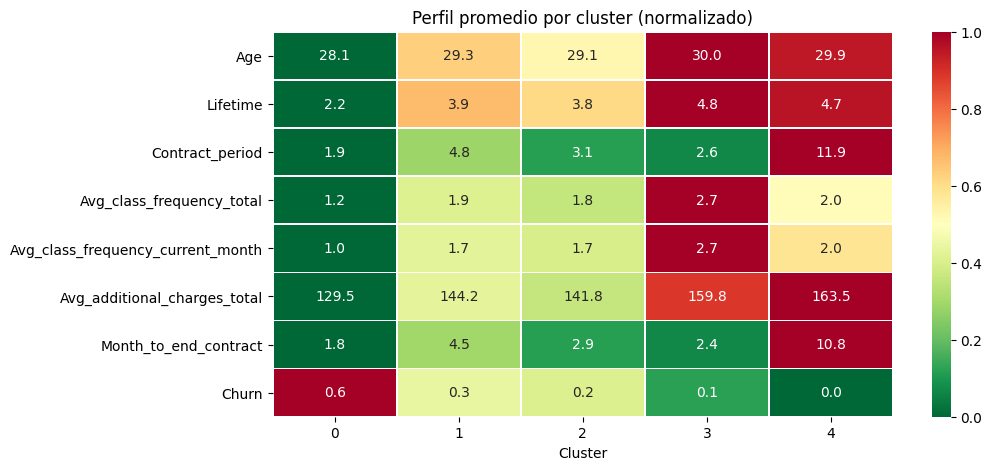

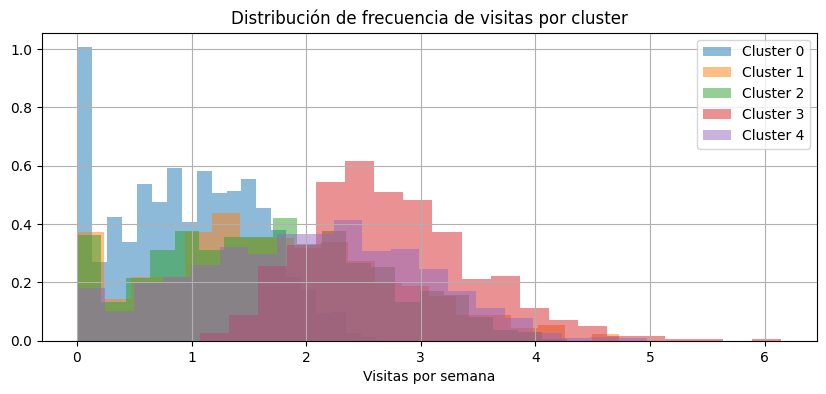

In [7]:
# Heatmap de perfiles por cluster
profile_cols = ['Age','Lifetime','Contract_period',
                'Avg_class_frequency_total',
                'Avg_class_frequency_current_month',
                'Avg_additional_charges_total',
                'Month_to_end_contract','Churn']

profile = df.groupby('cluster')[profile_cols].mean()
profile_norm = (profile - profile.min()) / (profile.max() - profile.min())

plt.figure(figsize=(10, 5))
sns.heatmap(profile_norm.T, annot=profile.T.round(1), fmt='.1f',
            cmap='RdYlGn_r', linewidths=0.5)
plt.title('Perfil promedio por cluster (normalizado)')
plt.xlabel('Cluster')
plt.show()

# Distribuciones de frecuencia por cluster
plt.figure(figsize=(10, 4))
for cluster in sorted(df['cluster'].unique()):
    df[df['cluster']==cluster]['Avg_class_frequency_current_month'].hist(
        bins=20, alpha=0.5, label=f'Cluster {cluster}', density=True)
plt.title('Distribución de frecuencia de visitas por cluster')
plt.xlabel('Visitas por semana')
plt.legend()
plt.show()

<div class="alert alert-block alert-success">
<b>Comentario del revisor (2da Iteracion)</b> <a class=“tocSkip”></a>

Bien hecho! Se nota claramente la segmentación entre los diferentes grupos ya que tienen un churn rate diferente
</div>

## Conclusiones y Recomendaciones

### Factores principales de churn
1. **Período de contrato corto** — clientes con contrato de 1 mes tienen churn del 57% (Cluster 3)
2. **Baja frecuencia de visitas** — menos de 1 visita/semana es la señal más fuerte de abandono
3. **Poca antigüedad** — clientes con menos de 3 meses son los más vulnerables
4. **Pocos meses restantes en contrato** — cuando queda 1 mes o menos, el riesgo se dispara

### Grupos objetivo
- **Cluster 3** → intervención urgente (churn 57%)
- **Cluster 4 y 0** → retención preventiva (churn 25-27%)
- **Clusters 1 y 2** → mantener satisfechos, son los más leales

### Recomendaciones
1. **Promover contratos anuales desde el registro** — ofrecer descuento del 10-15% 
   por contrato de 6 o 12 meses. El Cluster 2 (contrato ~12 meses) tiene solo 2% de churn.

2. **Programa de onboarding para nuevos clientes** — los primeros 3 meses son críticos.
   Asignar un entrenador de bienvenida, metas semanales y seguimiento de visitas.

3. **Alerta automática por inactividad** — si un cliente baja de 2 visitas/semana 
   durante 2 semanas seguidas, activar contacto proactivo (mensaje + clase grupal gratis).

4. **Potenciar clases grupales y programa de referidos** — los clientes con 
   Group_visits=1 y Promo_friends=1 muestran menor churn. Crear incentivos 
   para participación grupal genera comunidad y aumenta el costo de salida.

<div class="alert alert-block alert-success">
<b>Comentario general (3ra Iteracion)</b> <a class=“tocSkip”></a>

Muy buen trabajo, manejaste muy bien los datos previo al entrenamiento de tus modelos y analizaste muy bien los resultados.
    
Planteaste muy buenas conclusiones en base a los datos de tu análisis, un buen análisis siempre debe venir acompañado de recomendaciones que ayuden a la toma de decisiones que en este caso haz planteado sugerencias muy buenas en cuanto a los diferentes tipos de usuarios obtenidos.
    
    
Saludos!
</div>